# NumPy 3: Indexación

_Autor: Alejandra Cuellar_

Este notebook muestra cómo sacar del cubo de fotos de una estrella exactamente la parte que se necesita, en una línea y sin bucles. Cubre:

1. Un número y un rango: comas y `:`
2. La historia de un píxel
3. La máscara como índice

Este notebook asume los notebooks de NumPy 1 y 2 (qué es un array, `np.load`, `np.sum`, forma, ejes y `dtype`).

---

### Prompts de profundización

Al final de cada tema hay unos prompts para que los usen con su chatbot de confianza y profundicen más.

## 0. Prerrequisitos

Para correr este notebook, deben asegurarse de haber creado el virtual environment de python siguiendo las instrucciones del README. Una vez creado, selecciona el kernel del notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Para instalar python, el manejador de paquetes UV, los ambientes de conda y configurar Visual Studio Code para correr y editar Jupyter Notebooks en él, revisen los siguientes recursos:

- [Cómo instalar Anaconda y Jupyter](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [Instalación de UV](https://youtu.be/TJor7z8g8FA?si=QT2XVKeC29dYyDts)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

## 1. Un número y un rango: comas y `:`

Cargamos los tres archivos de la serie y las funciones para graficar.

In [1]:
import numpy as np
from plot_helpers import plot_frame, plot_light_curve

cube = np.load("../data/flux_cube.npy")
time = np.load("../data/time.npy")
mask = np.load("../data/aperture_mask.npy")

En el video 2 sacamos un número con un `[ ]` por eje. NumPy permite poner todos los índices en un solo `[ ]`, separados por comas.

In [2]:
print(cube[0][5][5]) #The photo, then the row, then the number
print(cube[0, 5, 5]) #Direct to the pixel

7896.526
7896.526


Un rango se escribe `inicio:fin`, y el fin no se incluye.

In [3]:
print(time[0:3])
print(time[:3]) #The default is the 0 index
print(time[:])

[0.         0.00138891 0.00277783]
[0.         0.00138891 0.00277783]
[0.00000000e+00 1.38891465e-03 2.77782930e-03 ... 1.99586859e+00
 1.99725750e+00 1.99864641e+00]


In [4]:
print(cube[0:3].shape)
print(cube[:].shape) #Without index are all the axis

(3, 11, 11)
(1440, 11, 11)


Los rangos se combinan con comas: el recuadro de 3 × 3 píxeles alrededor de la estrella, en la primera foto.

In [5]:
box = cube[0, 4:7, 4:7]

print(box)

[[3524.7532 5531.9917 1982.4039]
 [3504.841  7896.526  4320.892 ]
 [2001.4847 3058.5    1762.9657]]


En el video 1, con una sola foto, NumPy le ganó solo unas 2 veces al bucle sobre una lista. Repetimos la comparación con las primeras 170 fotos, que no tienen ninguna foto vacía.

In [6]:
block = cube[:170]
block_list = block.tolist()

print(block.size)

20570


In [7]:
%%timeit
total = 0.0
for photo in block_list:
    for row in photo:
        for value in row:
            total += value

507 μs ± 77.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [8]:
%%timeit
np.sum(block)

12.3 μs ± 413 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


**Prompts de profundización:**

- `¿Qué diferencia hay entre arr[0][5][5] y arr[0, 5, 5] en NumPy?`
- `¿Por qué en Python y NumPy el final de un rango (slice) no se incluye?`
- `¿Qué hace un paso en un slice, como arr[::2], y qué significan los índices negativos?`

## 2. La historia de un píxel

¿Cómo sacar el píxel de la estrella en las 1440 fotos? 

In [9]:
trap = cube[:][5][5] #Trap, is the first idea

print(trap.shape)
print(trap)
print(cube[5][5])

(11,)
[ 132.37833   305.43335   754.7451   1339.3999   3540.873    7889.2954
 4263.5933    210.32056    86.76425    81.225586   78.65272 ]
[ 132.37833   305.43335   754.7451   1339.3999   3540.873    7889.2954
 4263.5933    210.32056    86.76425    81.225586   78.65272 ]


Con `[ ]` encadenados, cada uno actúa sobre el resultado del anterior: `cube[:]` es todo el cubo, `[5]` la foto 5 y el otro `[5]` su fila 5. Con comas, cada índice va a su eje:

In [10]:
pixel = cube[:, 5, 5]

print(pixel.shape)
print(pixel[:3]) 

(1440,)
[7896.526 7873.591 7896.312]


Un número por foto: lo graficamos contra el tiempo.

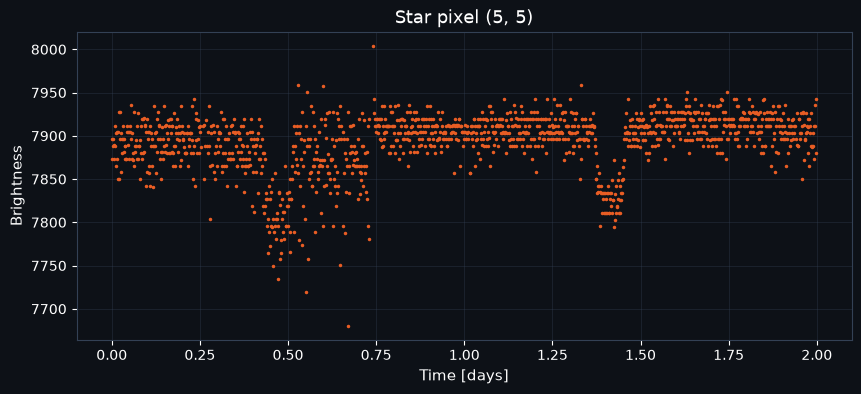

In [11]:
plot_light_curve(time, pixel, title="Star pixel (5, 5)")

Para comparar, un píxel de la esquina, que no es de la estrella.

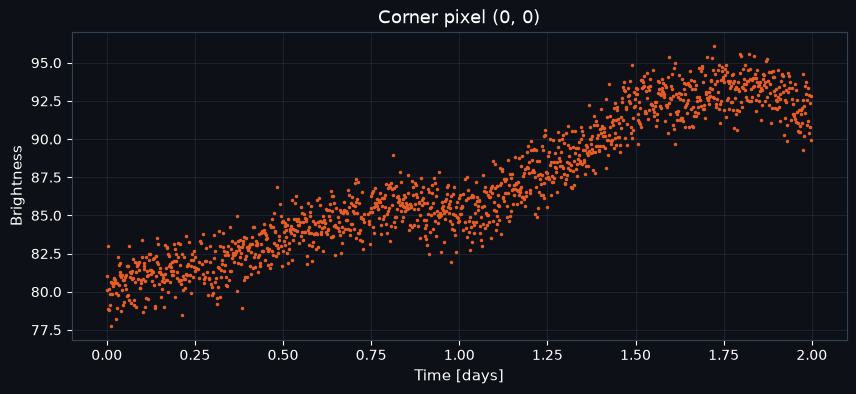

In [12]:
corner = cube[:, 0, 0]

plot_light_curve(time, corner, title="Corner pixel (0, 0)")

**Prompts de profundización:**

- `¿Por qué arr[:][5][5] no es lo mismo que arr[:, 5, 5] en NumPy?`
- `¿Qué es una serie de tiempo y cómo se guarda en un array de NumPy?`
- `¿Por qué una medición de un solo píxel tiene más ruido que la suma de varios píxeles?`

## 3. La máscara como índice

La máscara dice qué píxeles son de la estrella. Dibujada sobre la primera foto:

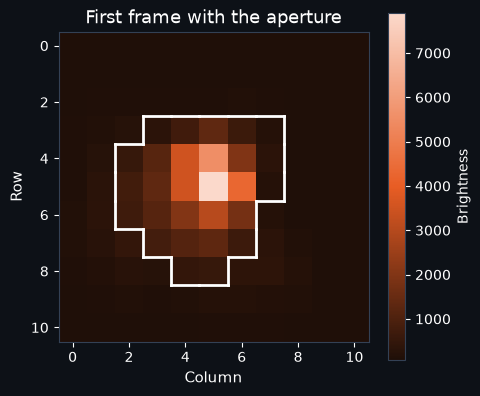

In [13]:
frame = cube[0]

plot_frame(frame, mask=mask, title="First frame with the aperture")

Usada como índice, la máscara saca el brillo de los píxeles donde dice `True`:

In [14]:
star = frame[mask]

print(star.shape)
print(star)

(28,)
[ 322.36768  723.32733 1350.9249   641.2662   224.89293  538.0298
 1199.8978  3524.7532  5531.9917  1982.4039   332.47366  750.3311
 1336.5138  3504.841   7896.526   4320.892    219.95128  701.40753
 1146.906   2001.4847  3058.5     1762.9657   793.4288  1130.3795
 1322.9064   680.4672   487.87872  542.4386 ]


El brillo de la estrella en la primera foto:

In [15]:
print(np.sum(star))

48030.15


La máscara también sirve en el cubo entero: una fila por foto, una columna por píxel de la estrella.

In [16]:
table = cube[:, mask]

print(table.shape)

(1440, 28)


**Prompts de profundización:**

- `¿Qué es la indexación booleana (boolean indexing) en NumPy y por qué el resultado es de una dimensión?`
- `¿En qué orden devuelve NumPy los elementos cuando indexo con una máscara de dos dimensiones?`
- `¿Cómo eligen los astrónomos qué píxeles de una imagen pertenecen a una estrella?`

## 4. ¿Qué viene?

Cambiamos un número del recuadro de la estrella. Solo tocamos `box`... ¿o no?

In [17]:
box = cube[0, 4:7, 4:7]
box[1, 1] = 0

print(cube[0, 5, 5])

0.0


## Referencias

- NumPy Developers. *NumPy documentation*. https://numpy.org/doc/stable/
- NumPy Developers. *Indexing on ndarrays*. https://numpy.org/doc/stable/user/basics.indexing.html

---

*Última actualización: octubre 2026*